<a href="https://colab.research.google.com/github/annKlv22/MFDP/blob/develop/eda_job_postings_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EDA: вакансии 2026 (Индия + США)

**Датасет:** [`fliarbi/job-postings-2026`](https://huggingface.co/datasets/fliarbi/job-postings-2026)
100 009 вакансий, 17 колонок, период: январь–июнь 2026

Только часть вакансий содержат зарплату, что мешает строить зарплатные бенчмарки и ухудшает карточку вакансии в продукте. Мы предсказываем сам факт раскрытия (задача бинарной классификации) и используем модель как propensity-score.

In [4]:
from pathlib import Path
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

warnings.filterwarnings("ignore", message="FigureCanvasAgg")

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 130, "savefig.bbox": "tight",
    "axes.titlesize": 12, "axes.titleweight": "bold", "font.size": 10,
})


def find_root() -> Path:
    # ищем корень репозитория по наличию data/train.parquet
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "train.parquet").exists():
            return p
    raise FileNotFoundError("Не найден /train.parquet — запустите scripts/download_data.py")


ROOT = find_root()
FIG = ROOT / "figures"
FIG.mkdir(exist_ok=True)
print("корень репозитория:", ROOT)


def save(fig, name: str) -> None:
    fig.savefig(FIG / name)
    plt.show()
    plt.close(fig)


def finish(fig, title: str) -> None:
    fig.suptitle(title, y=0.995, fontsize=13)
    fig.tight_layout(rect=(0, 0, 1, 0.93))

корень репозитория: /content


## 1. Загрузка данных и overview

In [6]:
def load_data(path: Path) -> pd.DataFrame:
    df = pd.read_parquet(path)

    # "" -> NaN: сводим два способа кодирования пропуска к одному
    df = df.replace("", pd.NA)

    df["posted_date"] = pd.to_datetime(df["posted_date"])
    df["month"] = df["posted_date"].dt.to_period("M").astype(str)

    # ЦЕЛЕВАЯ ПЕРЕМЕННАЯ: 1 = зарплата указана, 0 = нет
    df["y"] = df["salary_annual_usd"].notna().astype(int)

    # «Мягкий» Int64 -> float64: describe/groupby/matplotlib дружат с float лучше
    df["experience_years"] = df["experience_years"].astype("float64")

    # Длина заголовка — простейший текстовый признак
    df["title_len"] = df["title"].str.len()
    return df


df = load_data(ROOT / "train.parquet")
print("размер:", df.shape)
print(df.dtypes.to_string())
df.head(3).T

размер: (100009, 20)
posting_id                   object
posted_date          datetime64[ns]
title                        object
company                      object
role                         object
seniority                    object
category                     object
city                         object
region                       object
country                      object
remote                       object
experience_years            float64
education                    object
skills                       object
salary_annual_usd             Int64
company_domain               object
fliar_profile_url            object
month                        object
y                             int64
title_len                     int64


,0,1,2
posting_id,0065c048923a,008365bc7d00,00b93252154b
posted_date,2026-01-01 00:00:00,2026-01-01 00:00:00,2026-01-01 00:00:00
title,Diagnostic Medical Sonographer,"Neurologist Movement Disorders | Renton, WA | ...",Entry-Level Public Projects Engineer - Rail
company,CCRM Fertility,The Provider Finder,Olsson
role,healthcare,<NA>,<NA>
seniority,<NA>,<NA>,entry
category,<NA>,<NA>,<NA>
city,Austin,Renton,Omaha
region,Texas,Washington,Nebraska
country,US,US,US


In [7]:
pd.DataFrame({
    "уникальных": [df[c].nunique() for c in df.columns if c != "month"],
    "пропусков, %": [round(df[c].isna().mean() * 100, 1) for c in df.columns if c != "month"],
}, index=[c for c in df.columns if c != "month"])

,уникальных,"пропусков, %"
posting_id,99162,0.0
posted_date,181,0.0
title,69808,0.0
company,15922,0.0
role,23,27.6
seniority,8,55.5
category,2051,67.2
city,3082,3.3
region,91,5.4
country,2,0.0


## 2. Целевая переменная

Считаем баланс классов. Дальше — разбивка по стране, поскольку США и Индия — это два разных рынка и два разных набора источников данных.

In [8]:
print(df["y"].value_counts().to_string())
print(f"\nдоля раскрытия: {df['y'].mean():.2%}")

by_country = df.groupby("country")["y"].agg(n="size", disclosed="sum", rate="mean")
by_country["rate"] = (by_country["rate"] * 100).round(2)
print("\n", by_country.to_string())

y
0    85190
1    14819

доля раскрытия: 14.82%

              n  disclosed   rate
country                         
IN       19994       1056   5.28
US       80015      13763  17.20


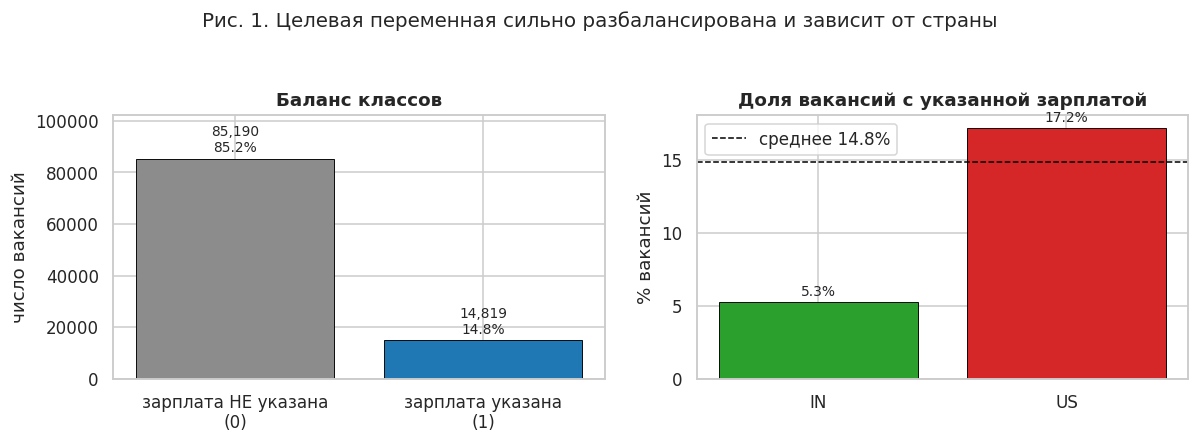

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
counts = df["y"].value_counts().sort_index()
bars = axes[0].bar(["зарплата НЕ указана\n(0)", "зарплата указана\n(1)"], counts.values,
                   color=["#8c8c8c", "#1f77b4"], edgecolor="black", linewidth=.6)
axes[0].set_title("Баланс классов")
axes[0].set_ylabel("число вакансий")
for b, v in zip(bars, counts.values):
    axes[0].text(b.get_x() + b.get_width() / 2, v + 1500, f"{v:,}\n{v / len(df):.1%}",
                 ha="center", va="bottom", fontsize=9)
axes[0].set_ylim(0, counts.max() * 1.2)

bars = axes[1].bar(by_country.index, by_country.rate, color=["#2ca02c", "#d62728"],
                   edgecolor="black", linewidth=.6)
axes[1].axhline(df["y"].mean() * 100, ls="--", c="black", lw=1,
                label=f"среднее {df['y'].mean():.1%}")
axes[1].set_title("Доля вакансий с указанной зарплатой")
axes[1].set_ylabel("% вакансий")
axes[1].legend()
for b, v in zip(bars, by_country.rate):
    axes[1].text(b.get_x() + b.get_width() / 2, v + .4, f"{v:.1f}%", ha="center", fontsize=9)
finish(fig, "Рис. 1. Целевая переменная сильно разбалансирована и зависит от страны")
save(fig, "01_target_balance.png")

Мы видим, что классы разбалансированы 85/15, поэтому
`accuracy` — плохая финальная метрика.

## 3. Пропуски

Смотрим на долю пропусков по исходным 17 колонкам.

In [10]:
miss = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "пропусков": df.isna().sum(),
    "пропусков, %": (df.isna().mean() * 100).round(2),
})
miss["уникальных"] = [np.nan if c == "month" else df[c].nunique() for c in df.columns]
miss

,dtype,пропусков,"пропусков, %",уникальных
posting_id,object,0,0.00,99162.0
posted_date,datetime64[ns],0,0.00,181.0
title,object,0,0.00,69808.0
company,object,0,0.00,15922.0
role,object,27589,27.59,23.0
seniority,object,55464,55.46,8.0
category,object,67203,67.20,2051.0
city,object,3309,3.31,3082.0
region,object,5429,5.43,91.0
country,object,0,0.00,2.0


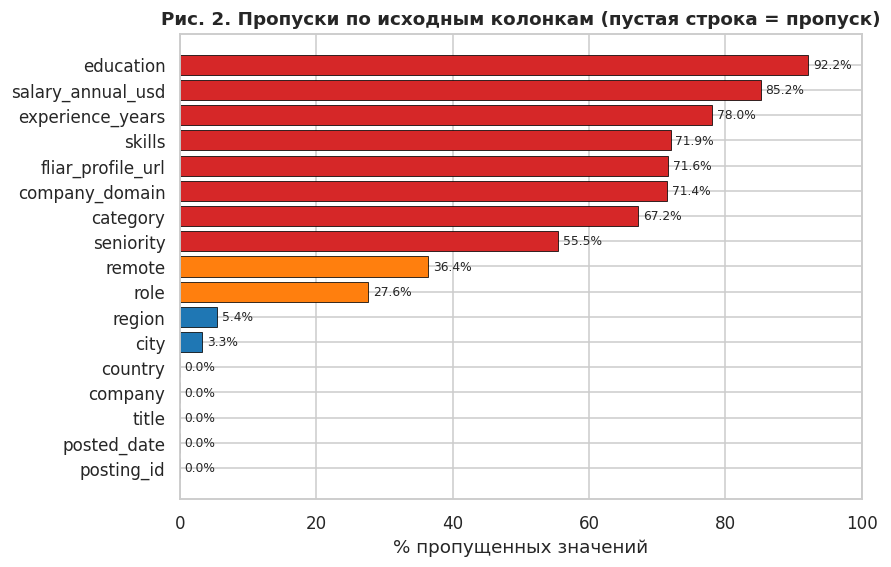

In [11]:
fig, ax = plt.subplots(figsize=(8, 5.5))
m = miss["пропусков, %"].drop(labels=["month", "y", "title_len"]).sort_values()
colors = ["#d62728" if v > 50 else "#ff7f0e" if v > 20 else "#1f77b4" for v in m.values]
ax.barh(m.index, m.values, color=colors, edgecolor="black", linewidth=.5)
for i, v in enumerate(m.values):
    ax.text(v + .7, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, 100)
ax.set_xlabel("% пропущенных значений")
ax.set_title("Рис. 2. Пропуски по исходным колонкам (пустая строка = пропуск)")
save(fig, "02_missing_values.png")

Практический вывод: колонки с пропуском >50% нельзя использовать как обычные
признаки, а **индикатор пропуска** — тем более.

## 4. Временная динамика


In [12]:
n_by_month = df.pivot_table(index="month", columns="country", values="y", aggfunc="size")
rate_by_month = df.pivot_table(index="month", columns="country", values="y", aggfunc="mean") * 100

print("вакансий по месяцам:\n", n_by_month.to_string())
print("\nдоля с зарплатой, %:\n", rate_by_month.round(1).to_string())

вакансий по месяцам:
 country     IN     US
month                
2026-01     38  19625
2026-02    563  14999
2026-03   1220  11333
2026-04   3033  10801
2026-05   4630  10205
2026-06  10510  13052

доля с зарплатой, %:
 country    IN    US
month              
2026-01  63.2   1.8
2026-02   3.9   4.6
2026-03   4.7   8.6
2026-04   2.2  25.8
2026-05   8.5  41.7
2026-06   4.7  36.1


Доля вакансий с зарплатой постоянно меняется: в США она растёт с 1.8% в январе до 41.7%
в мае, в Индии — падает с 63% до 4–8%. Одновременно меняется и объём
выборки: индийских вакансий в январе 38, в июне — 10 510.

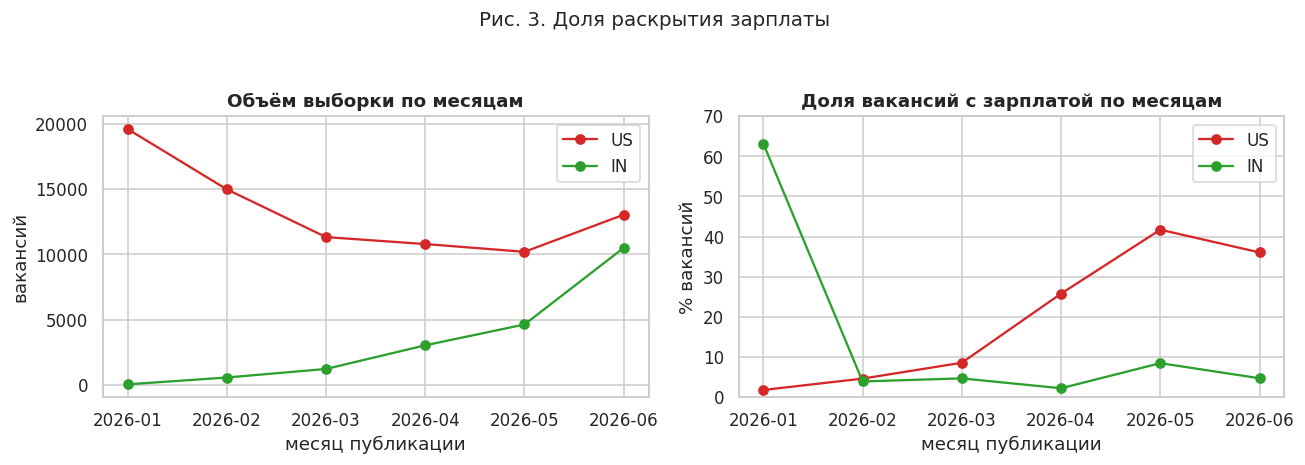

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for c, color in zip(["US", "IN"], ["#d62728", "#2ca02c"]):
    axes[0].plot(n_by_month.index, n_by_month[c], marker="o", label=c, color=color)
    axes[1].plot(rate_by_month.index, rate_by_month[c], marker="o", label=c, color=color)
axes[0].set_title("Объём выборки по месяцам")
axes[0].set_ylabel("вакансий")
axes[0].legend()
axes[1].set_title("Доля вакансий с зарплатой по месяцам")
axes[1].set_ylabel("% вакансий")
axes[1].set_ylim(0, 70)
axes[1].legend()
for ax in axes:
    ax.set_xlabel("месяц публикации")
finish(fig, "Рис. 3. Доля раскрытия зарплаты")
save(fig, "03_monthly_dynamics.png")

## 5. Сама зарплата

In [15]:
print(df.loc[df.y == 1, "salary_annual_usd"].describe().round(0).to_string())
print("\nпо странам:")
print(df[df.y == 1].groupby("country")["salary_annual_usd"].describe().round(0).to_string())
print("\n5 самых больших значений:", df.loc[df.y == 1, "salary_annual_usd"].nlargest(5).tolist())
print("5 самых маленьких:", df.loc[df.y == 1, "salary_annual_usd"].nsmallest(5).tolist())

count     14819.0
mean      68278.0
std       43353.0
min        1200.0
25%       37440.0
50%       55000.0
75%       90000.0
max      316800.0

по странам:
           count     mean      std      min      25%      50%      75%       max
country                                                                         
IN        1056.0  17080.0  23955.0   1200.0   3600.0   7770.0  24000.0  316800.0
US       13763.0  72207.0  41990.0  17888.0  39520.0  60000.0  94670.0  250000.0

5 самых больших значений: [316800, 273600, 250000, 250000, 250000]
5 самых маленьких: [1200, 1200, 1200, 1200, 1200]


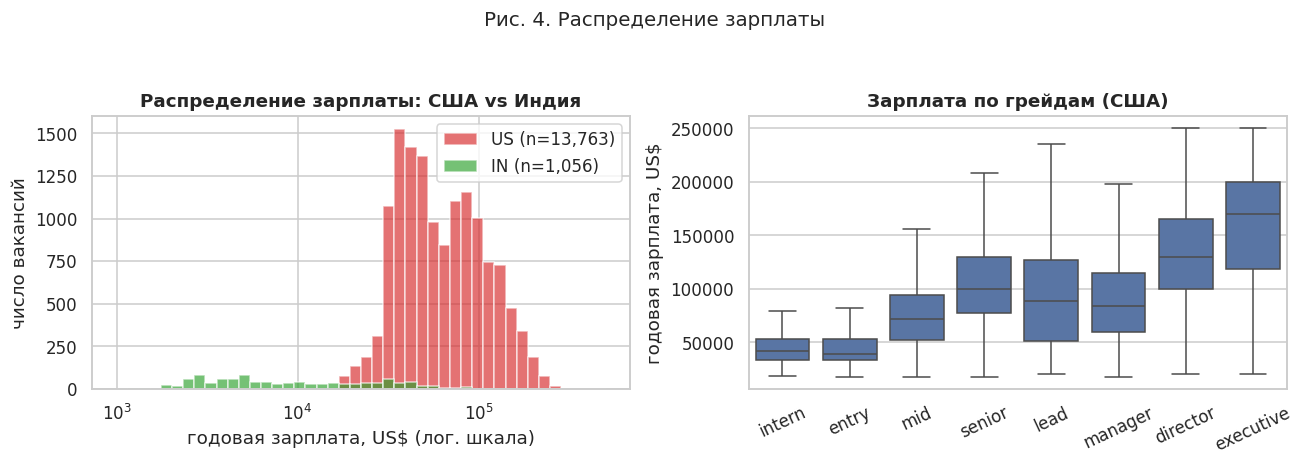

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

for c, color in zip(["US", "IN"], ["#d62728", "#2ca02c"]):
    s = df.loc[(df.y == 1) & (df.country == c), "salary_annual_usd"]
    axes[0].hist(s, bins=np.logspace(3, 5.7, 45), alpha=.65,
                 label=f"{c} (n={len(s):,})", color=color)
axes[0].set_xscale("log")
axes[0].set_xlabel("годовая зарплата, US$ (лог. шкала)")
axes[0].set_ylabel("число вакансий")
axes[0].set_title("Распределение зарплаты: США vs Индия")
axes[0].legend()

order = ["intern", "entry", "mid", "senior", "lead", "manager", "director", "executive"]
sub = df[(df.y == 1) & (df.country == "US") & (df.seniority.isin(order))]
sns.boxplot(data=sub, x="seniority", y="salary_annual_usd", order=order,
            ax=axes[1], showfliers=False)
axes[1].set_title("Зарплата по грейдам (США)")
axes[1].set_xlabel("")
axes[1].set_ylabel("годовая зарплата, US$")
axes[1].tick_params(axis="x", rotation=25)

finish(fig, "Рис. 4. Распределение зарплаты")
save(fig, "04_salary_distribution.png")

## 6. Категориальные признаки

Проверяем по очереди `role`, `seniority`, `remote`, `education`.

                        n  rate
role                           
software-eng         4138   8.1
design               2045   9.0
data                 1783   9.1
product              1803   9.7
legal                1125  11.0
devops-cloud          556  11.9
admin                3327  12.3
manufacturing        4850  13.2
healthcare          13909  13.2
science-research      708  14.5
education            2599  14.7
marketing            2725  15.1
hr                   1737  15.4
finance              5190  16.0
it-support            602  16.8
logistics            3057  16.8
security              596  17.6
construction         1813  18.3
sales                7468  19.8
customer-service     1909  21.4
operations           4553  24.7
retail-hospitality   3408  31.9
other                2519  43.0


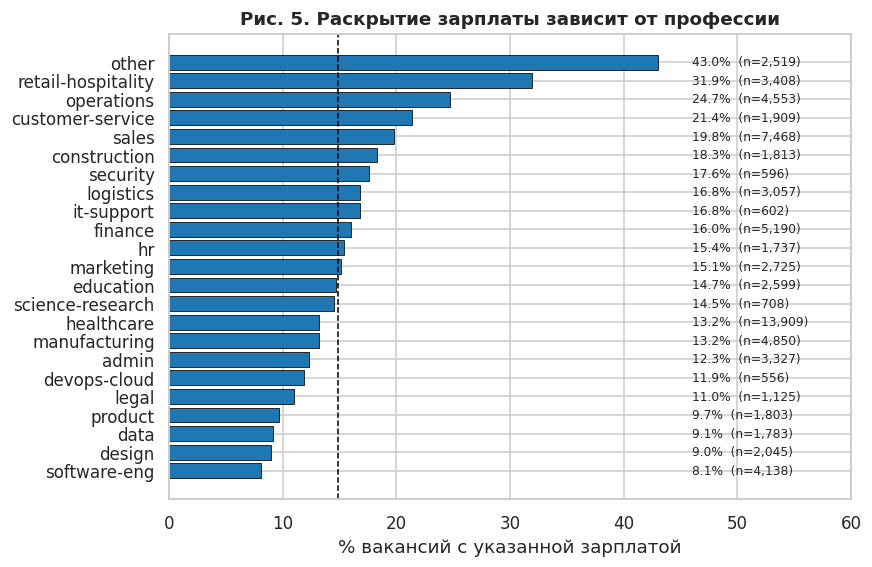

In [18]:
role_tbl = df.groupby("role")["y"].agg(n="size", rate="mean")
role_tbl = role_tbl[role_tbl.n >= 200].sort_values("rate")
role_tbl["rate"] = (role_tbl["rate"] * 100).round(1)
print(role_tbl.to_string())

fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(role_tbl.index, role_tbl.rate, color="#1f77b4", edgecolor="black", linewidth=.5)
for i, (r, n) in enumerate(zip(role_tbl.rate, role_tbl.n)):
    ax.text(46, i, f"{r:.1f}%  (n={n:,})", va="center", fontsize=8)
ax.axvline(df["y"].mean() * 100, ls="--", c="black", lw=1)
ax.set_xlim(0, 60)
ax.set_xlabel("% вакансий с указанной зарплатой")
ax.set_title("Рис. 5. Раскрытие зарплаты зависит от профессии")
save(fig, "05_disclosure_by_role.png")

In [19]:
for col in ["seniority", "remote", "education"]:
    t = df.groupby(col)["y"].agg(n="size", rate="mean")
    t["rate"] = (t["rate"] * 100).round(1)
    print(f"--- {col} ---")
    print(t.sort_values("rate").to_string(), "\n")

--- seniority ---
               n  rate
seniority             
intern      2085   9.0
executive   1411   9.9
lead        4902  12.1
manager    15156  14.3
senior      7777  14.9
director    3886  15.7
entry       7136  26.4
mid         2192  40.5 

--- remote ---
            n  rate
remote             
onsite  61671  11.2
remote   1591  15.7
hybrid    309  21.0 

--- education ---
                n  rate
education              
Doctorate      82  15.9
Bachelor     5632  36.5
Associate     295  37.6
Master        234  41.0
High school  1591  43.9 



## 7. Навыки

In [20]:
has_skills = df["skills"].notna()
print("доля вакансий с навыками:", f"{has_skills.mean():.1%}")

# проверяем гипотезу «навыки зависят от remote»
print(pd.crosstab(df["remote"], has_skills, normalize="index").round(3).to_string())
print()
print(pd.crosstab(df["country"], has_skills, normalize="index").round(3).to_string())

доля вакансий с навыками: 28.1%
skills  False  True 
remote              
hybrid  0.757  0.243
onsite  1.000  0.000
remote  0.855  0.145

skills   False  True 
country              
IN       0.030  0.970
US       0.892  0.108


In [21]:
# "python|sql|excel" -> ["python", "sql", "excel"] -> длинная таблица
skills_long = df.loc[has_skills, "skills"].str.split("|")
print("навыков на вакансию:", skills_long.str.len().describe().round(2).to_dict())
print("различных навыков:", skills_long.explode().nunique())

top_skills = skills_long.explode().value_counts().head(10)
print("\nтоп-10:", top_skills.to_dict())

навыков на вакансию: {'count': 28067.0, 'mean': 7.48, 'std': 5.32, 'min': 1.0, '25%': 4.0, '50%': 6.0, '75%': 10.0, 'max': 62.0}
различных навыков: 54723

топ-10: {'python': 2394, 'excel': 1788, 'sql': 1727, 'aws': 1194, 'java': 1075, 'javascript': 921, 'project management': 815, 'communication skills': 815, 'azure': 760, 'sales': 717}


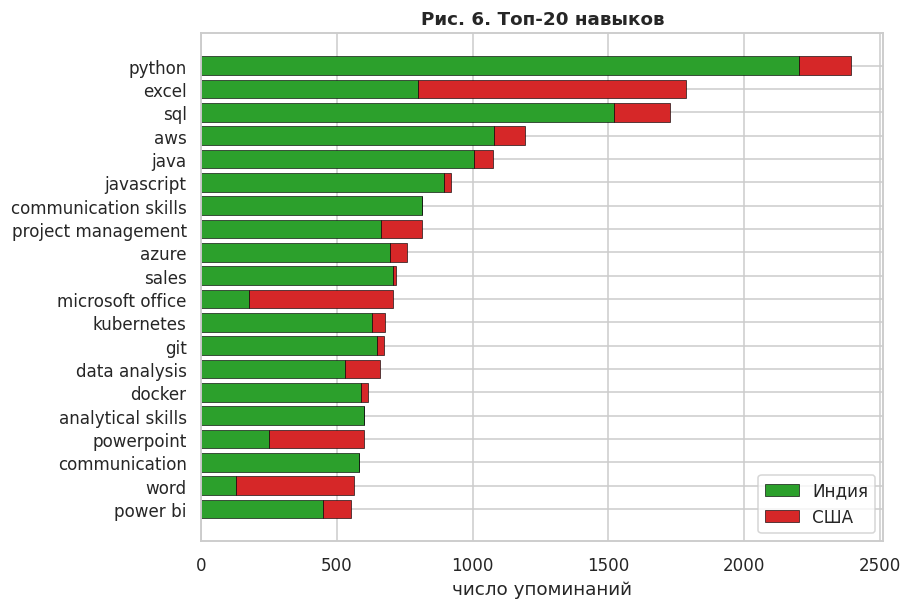

In [23]:
sk_tbl = (df.loc[has_skills, ["country"]]
          .assign(skill=skills_long)
          .explode("skill")
          .value_counts(["skill", "country"])
          .unstack(fill_value=0))
sk_tbl["total"] = sk_tbl.sum(axis=1)
sk_tbl = sk_tbl.sort_values("total", ascending=False).head(20)

fig, ax = plt.subplots(figsize=(8, 6))
order = sk_tbl.index[::-1]
ax.barh(order, sk_tbl.loc[order, "IN"], color="#2ca02c", label="Индия",
        edgecolor="black", linewidth=.4)
ax.barh(order, sk_tbl.loc[order, "US"], left=sk_tbl.loc[order, "IN"], color="#d62728",
        label="США", edgecolor="black", linewidth=.4)
ax.set_xlabel("число упоминаний")
ax.set_title("Рис. 6. Топ-20 навыков")
ax.legend()
save(fig, "06_top_skills.png")

## 8. Компании: политика раскрытия



In [24]:
cc = df["company"].value_counts()
print("компаний:", len(cc))
print("вакансий у топ-1:", f"{cc.head(1).sum() / len(df):.1%}")
print("вакансий у топ-10:", f"{cc.head(10).sum() / len(df):.1%}")
print("вакансий у топ-100:", f"{cc.head(100).sum() / len(df):.1%}")

comp = df.groupby("company")["y"].agg(n="size", n_sal="sum")
comp["rate"] = comp["n_sal"] / comp["n"]
comp5 = comp[comp.n >= 5]
print(f"\nкомпаний с >=5 вакансиями: {len(comp5)}")
print(f"ни разу не раскрыли: {(comp5.rate == 0).mean():.1%}")
print(f"раскрыли в >=90% случаев: {(comp5.rate >= .9).mean():.1%}")

компаний: 15922
вакансий у топ-1: 0.9%
вакансий у топ-10: 6.4%
вакансий у топ-100: 24.8%

компаний с >=5 вакансиями: 3622
ни разу не раскрыли: 56.2%
раскрыли в >=90% случаев: 1.2%


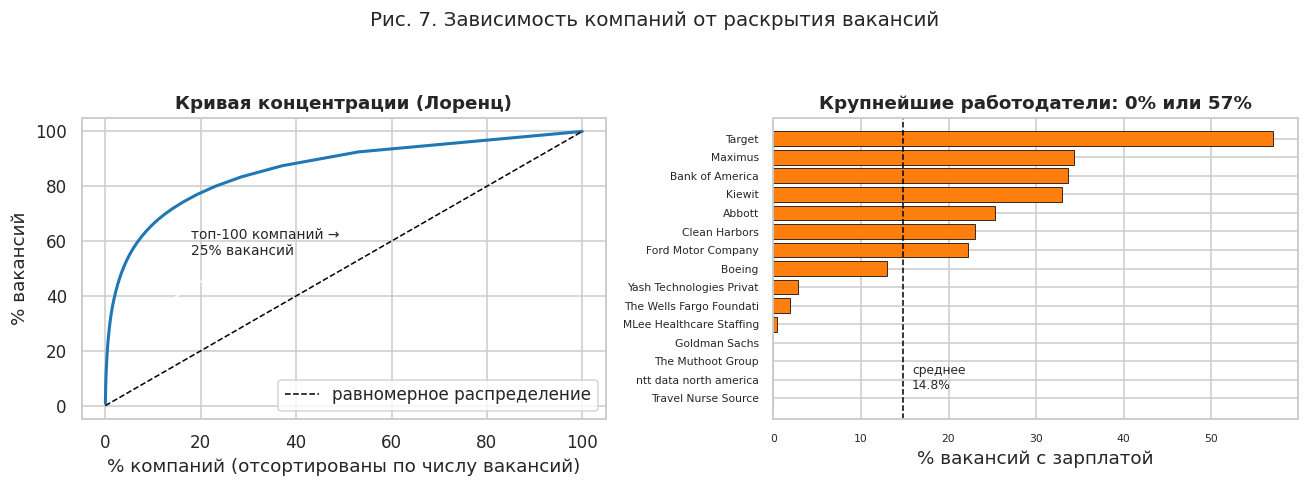

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))

cum = (cc.sort_values(ascending=False).cumsum() / len(df) * 100).values
x = np.arange(1, len(cc) + 1) / len(cc) * 100
axes[0].plot(x, cum, color="#1f77b4", lw=2)
axes[0].plot([0, 100], [0, 100], ls="--", c="black", lw=1, label="равномерное распределение")
axes[0].set_xlabel("% компаний (отсортированы по числу вакансий)")
axes[0].set_ylabel("% вакансий")
axes[0].set_title("Кривая концентрации (Лоренц)")
axes[0].legend()
axes[0].annotate(f"топ-100 компаний →\n{cc.head(100).sum() / len(df):.0%} вакансий",
                 xy=(0.6, 24.8), xytext=(18, 55), fontsize=9,
                 arrowprops=dict(arrowstyle="->", lw=1))

top15 = comp.sort_values("n", ascending=False).head(15).sort_values("rate")
axes[1].barh(top15.index.str.slice(0, 24), top15.rate * 100, color="#ff7f0e",
             edgecolor="black", linewidth=.5)
axes[1].axvline(df["y"].mean() * 100, ls="--", c="black", lw=1)
axes[1].text(df["y"].mean() * 100 + 1, 0.5, f"среднее\n{df['y'].mean():.1%}", fontsize=8)
axes[1].set_xlabel("% вакансий с зарплатой")
axes[1].set_title("Крупнейшие работодатели: 0% или 57%")
axes[1].tick_params(labelsize=7)

finish(fig, "Рис. 7. Зависимость компаний от раскрытия вакансий")
save(fig, "07_companies.png")

15 922 компании на 100 тыс. вакансий. У компаний с ≥5 вакансиями **56% не раскрыли зарплату
ни разу**, и только 1% раскрывают почти всегда.

## 9. Опыт и текстовые признаки

In [27]:
print(df["experience_years"].describe().round(2).to_string())
print("\nдлина заголовка:", df["title_len"].describe().round(1).to_dict())
print("заголовков с '|':", f"{df['title'].str.contains('|', regex=False, na=False).mean():.2%}")

count    21996.00
mean         5.05
std          3.64
min          1.00
25%          2.00
50%          4.00
75%          7.00
max         27.00

длина заголовка: {'count': 100009.0, 'mean': 32.5, 'std': 17.0, 'min': 2.0, '25%': 20.0, '50%': 29.0, '75%': 41.0, 'max': 213.0}
заголовков с '|': 0.96%


               n  rate
exp_bucket            
1           2657  22.8
2           3306  17.3
3           3249  14.7
4-5         5804  12.2
6-8         3902  11.0
9-12        2245  12.5
13+          833  13.2


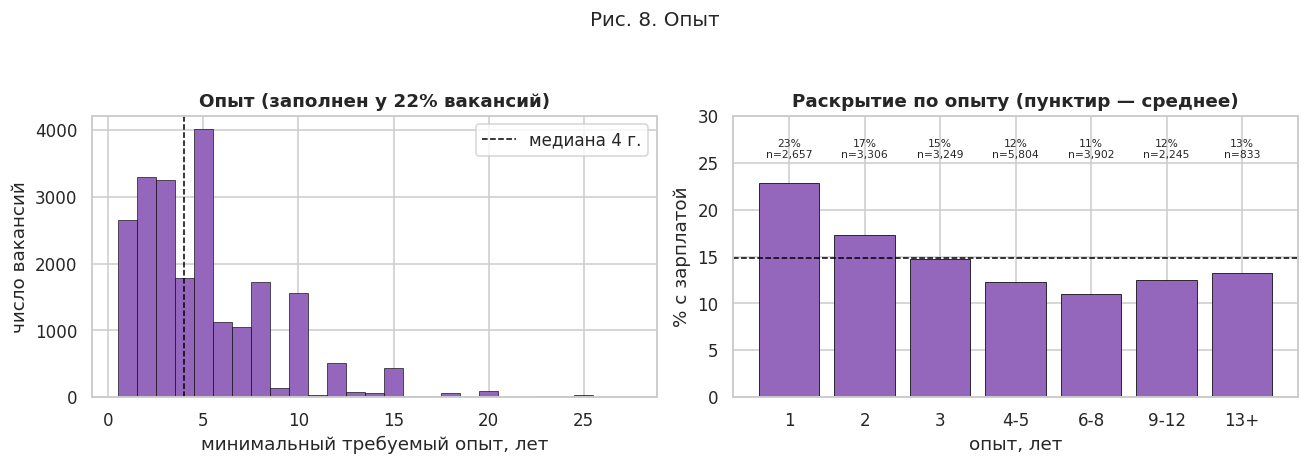

In [29]:
bins = [0, 1, 2, 3, 5, 8, 12, 100]
labels = ["1", "2", "3", "4-5", "6-8", "9-12", "13+"]
df["exp_bucket"] = pd.cut(df["experience_years"], bins=bins, labels=labels)
exp_tbl = df.groupby("exp_bucket", observed=False)["y"].agg(n="size", rate="mean")
print(exp_tbl.assign(rate=lambda d: (d.rate * 100).round(1)).to_string())

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
axes[0].hist(df["experience_years"].dropna(), bins=np.arange(.5, 28.5, 1),
             color="#9467bd", edgecolor="black", linewidth=.4)
axes[0].axvline(df["experience_years"].median(), c="black", ls="--", lw=1,
                label=f"медиана {df['experience_years'].median():.0f} г.")
axes[0].set_xlabel("минимальный требуемый опыт, лет")
axes[0].set_ylabel("число вакансий")
axes[0].set_title("Опыт (заполнен у 22% вакансий)")
axes[0].legend()

axes[1].bar(exp_tbl.index.astype(str), exp_tbl.rate * 100, color="#9467bd",
            edgecolor="black", linewidth=.5)
axes[1].axhline(df["y"].mean() * 100, ls="--", c="black", lw=1)
for i, (r, n) in enumerate(zip(exp_tbl.rate * 100, exp_tbl.n)):
    axes[1].text(i, 25.5, f"{r:.0f}%\nn={n:,}", ha="center", fontsize=7)
axes[1].set_ylim(0, 30)
axes[1].set_xlabel("опыт, лет")
axes[1].set_ylabel("% с зарплатой")
axes[1].set_title("Раскрытие по опыту (пунктир — среднее)")

finish(fig, "Рис. 8. Опыт")
save(fig, "08_experience.png")

`experience_years` заполнен у 22% вакансий.
Связь с раскрытием слабая и **отрицательная**: чем больше требуемый опыт, тем реже
указывают зарплату (22.8% при опыте 1 год против ~11% при 6–8 годах).

## 10. Профессия × месяц


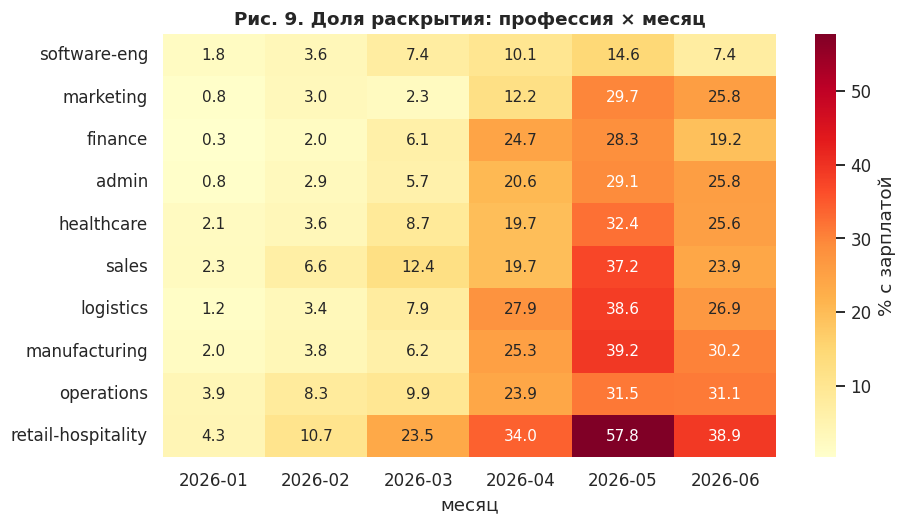

In [31]:
top_roles = df["role"].value_counts().head(10).index
hm = (df[df.role.isin(top_roles)]
      .pivot_table(index="role", columns="month", values="y", aggfunc="mean") * 100)
hm = hm.loc[hm.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(9, 5))
sns.heatmap(hm, annot=True, fmt=".1f", cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "% с зарплатой"})
ax.set_title("Рис. 9. Доля раскрытия: профессия × месяц")
ax.set_xlabel("месяц")
ax.set_ylabel("")
save(fig, "09_heatmap_role_month.png")

Тепловая карта показывает, что сдвиг во времени задевает
**все профессии одновременно**.

## 11. Считаем базовые ориентиры


In [32]:
base = df["y"].mean()

print(f"доля класса 1 (база PR-AUC / Average Precision): {base:.3f}")
print(f"accuracy константы 'всегда 0': {1 - base:.3f}")
print(f"accuracy константы 'всегда 1': {base:.3f}")
print("ROC-AUC случайного ранжирования: 0.500")


def binary_metrics(y_true, y_pred) -> dict:
    # precision / recall / F1 / accuracy «руками», без sklearn
    tp = int(((y_true == 1) & (y_pred == 1)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum())
    fn = int(((y_true == 1) & (y_pred == 0)).sum())
    tn = int(((y_true == 0) & (y_pred == 0)).sum())
    prec, rec = tp / (tp + fp), tp / (tp + fn)
    return {"precision": round(prec, 3), "recall": round(rec, 3),
            "f1": round(2 * prec * rec / (prec + rec), 3),
            "accuracy": round((tp + tn) / len(y_true), 3)}

rule = (df["country"] == "US").astype(int)
print("\nправило 'US -> 1':", binary_metrics(df["y"], rule))

доля класса 1 (база PR-AUC / Average Precision): 0.148
accuracy константы 'всегда 0': 0.852
accuracy константы 'всегда 1': 0.148
ROC-AUC случайного ранжирования: 0.500

правило 'US -> 1': {'precision': 0.172, 'recall': 0.929, 'f1': 0.29, 'accuracy': 0.327}


* `accuracy` константы «всегда 0» = 85.2% — модель не находит
  ни одной вакансии с зарплатой из-за сильного дисбаланса;
* `PR-AUC` константы = 14.8% (доля положительного класса);
* `ROC-AUC` константы = 50% (случайное угадывание).

Правило «все вакансии из США — с зарплатой» даёт **recall 93%**, но **precision 17%**
и **accuracy 33%**. Поэтому accuracy здесь не отражает реальную картину.

## 12. Финальный вывод по данным

| Наблюдение | Следствие для модели |
|---|---|
| Классы 85/15 | accuracy бесполезна → PR-AUC, ROC-AUC, precision/recall (так как более устойчивы к дисбалансу) |
| Раскрытие 17.2% (US) vs 5.3% (IN) | `country` — обязательный признак, но также и источник смещения |
| Рост раскрытия в US с 1.8% (янв) до 41.7% (май) | только временной split, иначе утечка |
| 56% компаний с ≥5 вакансиями не раскрывают зарплаты никогда | GroupKFold по `company` |
| 847 дублирующихся `posting_id` (репосты в другие месяцы) | дедупликация по `posting_id` перед сплитом |

In [33]:
summary = {
    "строк": len(df),
    "колонок (исходно)": 17,
    "компаний": df["company"].nunique(),
    "доля класса 1": round(df["y"].mean() * 100, 2),
    "медиана зарплаты US": int(df.loc[(df.y == 1) & (df.country == "US"), "salary_annual_usd"].median()),
    "медиана зарплаты IN": int(df.loc[(df.y == 1) & (df.country == "IN"), "salary_annual_usd"].median()),
    "дублей posting_id": len(df) - df["posting_id"].nunique(),
}
summary

{'строк': 100009,
 'колонок (исходно)': 17,
 'компаний': 15922,
 'доля класса 1': np.float64(14.82),
 'медиана зарплаты US': 60000,
 'медиана зарплаты IN': 7770,
 'дублей posting_id': 847}